# Hồi quy tuyến tính đa biến dự đoán ADR
## Hotel Booking Demand

## 5.1. Khởi tạo thư viện và đường dẫn

`pandas`/`numpy` xử lý dữ liệu, `matplotlib` vẽ biểu đồ và `scikit-learn` hỗ trợ tiền xử lý, huấn luyện, đánh giá. Notebook tìm thư mục dự án ở thư mục hiện tại hoặc thư mục cha; cấu trúc dự kiến có `data/processed/` và `results/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").exists() and (BASE_DIR.parent / "data").exists():
    BASE_DIR = BASE_DIR.parent
DATA_PATH = BASE_DIR / "data" / "processed" / "hotel_bookings_cleaned_pre_capping.csv"
FIGURE_DIR = BASE_DIR / "results" / "figures" / "regression"
TABLE_DIR = BASE_DIR / "results" / "tables" / "regression"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", BASE_DIR, "\nData:", DATA_PATH)

Project: c:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand 
Data: c:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\data\processed\hotel_bookings_cleaned_pre_capping.csv


## 5.2. Đọc và kiểm tra dữ liệu

Kiểm tra kích thước và một số dòng đầu để xác nhận dữ liệu được nạp đúng. File đầu vào đã qua làm sạch chung nhưng chưa Capping riêng cho mô hình hồi quy.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy {DATA_PATH}. Kiểm tra thư mục data/processed/.")
df = pd.read_csv(DATA_PATH)
print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (86633, 38)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,total_of_special_requests,reservation_status,reservation_status_date,agent_was_missing,children_was_missing,country_was_missing,has_company,total_guests,total_nights,arrival_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0,Check-Out,2015-07-02,1,0,0,0,1,1,2015-07-01
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,0,Check-Out,2015-07-02,0,0,0,0,1,1,2015-07-01
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,1,Check-Out,2015-07-03,0,0,0,0,2,2,2015-07-01
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,0,Check-Out,2015-07-03,1,0,0,0,2,2,2015-07-01
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,1,Check-Out,2015-07-03,0,0,0,0,2,2,2015-07-01


## 5.3. Lựa chọn biến

Biến mục tiêu là `adr`, đại diện cho giá phòng trung bình mỗi ngày. Mô hình sử dụng **7 biến số** và **6 biến phân loại**. Biến phân loại sẽ được mã hóa thành dạng số ở bước tiền xử lý.

In [3]:
target = "adr"
numeric_features = ["lead_time", "adults", "children", "stays_in_weekend_nights", "stays_in_week_nights", "booking_changes", "total_of_special_requests"]
categorical_features = ["hotel", "arrival_date_month", "market_segment", "customer_type", "meal", "is_repeated_guest"]
features = numeric_features + categorical_features
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset thiếu các cột: {missing_columns}")
data = df[required_columns].copy()
for col in numeric_features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[target])
X, y = data[features].copy(), data[target].copy()
print("Kích thước dùng cho hồi quy:", data.shape)
print("Biến số:", len(numeric_features), "| Biến phân loại:", len(categorical_features))

Kích thước dùng cho hồi quy: (86633, 14)
Biến số: 7 | Biến phân loại: 6


## 5.4. Chia train/test

Dữ liệu được chia **80% train, 20% test**. Train dùng để tính ngưỡng Capping và huấn luyện; test được giữ riêng để đánh giá mô hình trên các mẫu chưa dùng để học. `random_state=42` giúp tái lập cách chia và hạn chế data leakage.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()
display(pd.DataFrame({"Tập": ["Train", "Test"], "Số mẫu": [len(X_train), len(X_test)], "Tỷ lệ": [f"{len(X_train)/len(X):.1%}", f"{len(X_test)/len(X):.1%}"]}))

,Tập,Số mẫu,Tỷ lệ
0,Train,69306,80.0%
1,Test,17327,20.0%


## 5.5. Capping một số biến đầu vào

Capping giới hạn giá trị cực đoan thay vì xóa bản ghi. Áp dụng cho `lead_time`, `stays_in_weekend_nights` và `stays_in_week_nights`, theo ngưỡng **Q1 − 3×IQR** và **Q3 + 3×IQR**, trong đó IQR = Q3 − Q1. Ngưỡng chỉ tính trên train rồi áp dụng giống nhau cho train/test. Không Capping `adr` vì đây là biến mục tiêu.

In [5]:
cap_columns = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights"]
cap_bounds = {}
for col in cap_columns:
    q1, q3 = X_train[col].quantile(0.25), X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 3 * iqr, q3 + 3 * iqr
    cap_bounds[col] = (lower, upper)
    X_train.loc[:, col] = X_train[col].clip(lower=lower, upper=upper)
    X_test.loc[:, col] = X_test[col].clip(lower=lower, upper=upper)
cap_summary = pd.DataFrame([{"Biến": col, "Ngưỡng dưới": b[0], "Ngưỡng trên": b[1]} for col, b in cap_bounds.items()])
display(cap_summary.round(4))

,Biến,Ngưỡng dưới,Ngưỡng trên
0,lead_time,-327.0,464.0
1,stays_in_weekend_nights,-6.0,8.0
2,stays_in_week_nights,-8.0,13.0


### Nhận xét về Capping

Các giá trị nằm ngoài ngưỡng được đưa về giới hạn gần nhất. Cách này giảm ảnh hưởng của một số giá trị cực đoan mà vẫn giữ lại bản ghi; tuy nhiên, Capping không đảm bảo dữ liệu trở thành phân phối chuẩn.

## 5.6. Pipeline tiền xử lý

- Biến số: điền giá trị thiếu bằng median, ít nhạy với ngoại lai hơn trung bình.
- Biến phân loại: điền giá trị thiếu bằng nhóm xuất hiện nhiều nhất, sau đó dùng **One-Hot Encoding** để tạo các cột nhị phân.
- `ColumnTransformer` kết hợp hai quy trình. Đặt các bước trong pipeline giúp tiền xử lý được khớp trên train và áp dụng nhất quán lên test.

In [6]:
numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numeric_features), ("cat", categorical_transformer, categorical_features)])
print("Đã tạo pipeline tiền xử lý.")

Đã tạo pipeline tiền xử lý.


## 5.7. Xây dựng và huấn luyện mô hình

Pipeline gồm bước tiền xử lý và `LinearRegression`. Mô hình học hệ số từ tập train, sau đó dự đoán ADR trên tập test để đánh giá khả năng áp dụng với dữ liệu chưa dùng để học.

In [7]:
model = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", LinearRegression())])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Huấn luyện hoàn tất. Train:", len(X_train), "| Test:", len(X_test))

Huấn luyện hoàn tất. Train: 69306 | Test: 17327


## 5.8. Đánh giá mô hình

- **R²:** mức độ mô hình giải thích biến thiên ADR trên tập test.
- **MAE:** sai số tuyệt đối trung bình giữa thực tế và dự đoán.
- **RMSE:** căn bậc hai của trung bình bình phương sai số; nhạy hơn với sai số lớn.

MAE và RMSE cùng đơn vị với ADR. Nên xem các chỉ số cùng nhau thay vì chỉ dựa vào một chỉ số.

In [8]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
n_encoded_features = len(feature_names)
metrics = pd.DataFrame({"Chỉ số": ["R²", "MAE", "RMSE", "Số đặc trưng sau mã hóa"], "Giá trị": [r2, mae, rmse, n_encoded_features]})
display(metrics.round(4))

,Chỉ số,Giá trị
0,R²,0.5451
1,MAE,25.0572
2,RMSE,34.2619
3,Số đặc trưng sau mã hóa,40.0000


### Diễn giải kết quả

Theo báo cáo, mô hình đạt khoảng **R² = 0,5451**, **MAE = 25,06**, **RMSE = 34,26**. R² cho thấy mô hình giải thích khoảng 54,51% biến thiên ADR trên tập test. Sai số vẫn còn đáng kể; RMSE lớn hơn MAE cũng gợi ý một số trường hợp có sai số lớn. Hãy đối chiếu với kết quả khi chạy notebook để bảo đảm dùng cùng phiên bản dữ liệu/code.

## 5.9. Phân tích hệ số hồi quy

Hệ số dương/âm cho biết chiều của mối liên hệ mà mô hình ước lượng khi giữ các biến khác cố định. Với biến phân loại đã mã hóa, hệ số thể hiện chênh lệch so với nhóm tham chiếu. Hệ số lớn không nhất thiết đồng nghĩa biến quan trọng nhất vì các biến có thể khác thang đo; hệ số cũng không chứng minh quan hệ nhân quả.

In [9]:
regressor = model.named_steps["regressor"]
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": regressor.coef_})
coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs_Coefficient", ascending=False)
print(f"Intercept: {regressor.intercept_:.6f}")
display(coef_df.drop(columns=["Abs_Coefficient"]).head(15).round(4))

Intercept: 55.273198


,Feature,Coefficient
28,cat__market_segment_Undefined,-111.0350
22,cat__market_segment_Complementary,-62.9398
27,cat__market_segment_Online TA,44.5910
24,cat__market_segment_Direct,43.6002
10,cat__arrival_date_month_August,42.6264
36,cat__meal_SC,-40.5090
21,cat__market_segment_Aviation,35.5103
14,cat__arrival_date_month_July,31.2975
13,cat__arrival_date_month_January,-30.5298
34,cat__meal_FB,29.6103


## 5.10. ADR thực tế và ADR dự đoán

Đường nét đứt là dự đoán hoàn hảo. Điểm càng gần đường này thì dự đoán càng sát; điểm càng xa thì sai số càng lớn. Nếu các điểm ở vùng ADR cao thường nằm dưới đường tham chiếu, mô hình có xu hướng dự đoán thấp ở vùng đó.

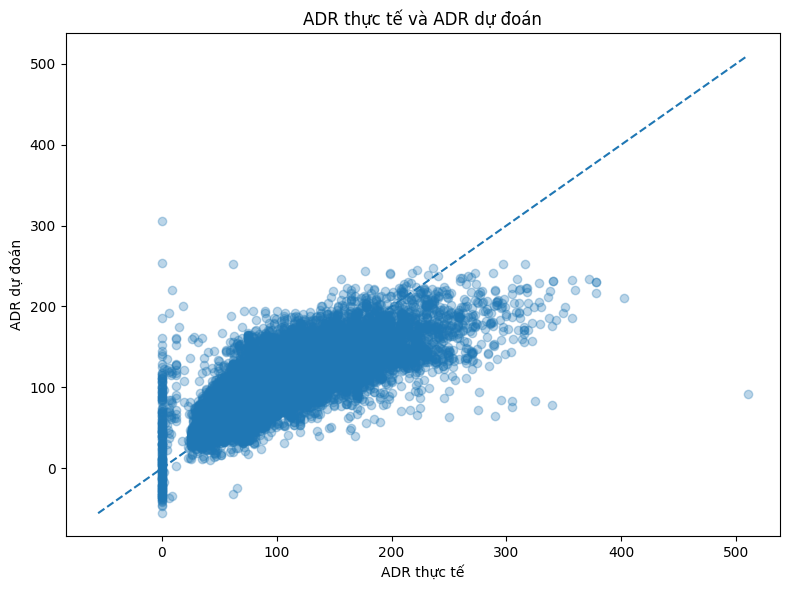

Đã lưu: c:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\regression\actual_vs_predicted.png


In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
min_value = min(y_test.min(), np.min(y_pred))
max_value = max(y_test.max(), np.max(y_pred))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("ADR thực tế")
plt.ylabel("ADR dự đoán")
plt.title("ADR thực tế và ADR dự đoán")
plt.tight_layout()
actual_pred_path = FIGURE_DIR / "actual_vs_predicted.png"
plt.savefig(actual_pred_path, dpi=300, bbox_inches="tight")
plt.show()
print("Đã lưu:", actual_pred_path)

## 5.11. Biểu đồ phần dư (Residual Plot)

Phần dư được tính bằng **thực tế − dự đoán**. Phần dư dương nghĩa là mô hình dự đoán thấp hơn thực tế; phần dư âm nghĩa là dự đoán cao hơn thực tế. Phần dư phân tán ngẫu nhiên quanh 0 thường là dấu hiệu phù hợp hơn; mẫu hình rõ hoặc độ phân tán thay đổi có thể cho thấy mô hình chưa mô tả hết cấu trúc dữ liệu.

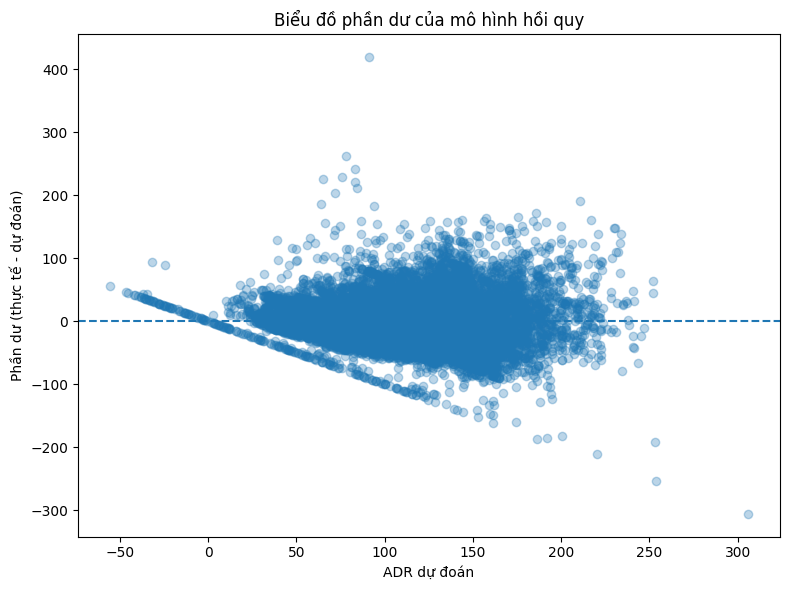

Đã lưu: c:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\regression\residual_plot.png


In [11]:
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")
plt.xlabel("ADR dự đoán")
plt.ylabel("Phần dư (thực tế - dự đoán)")
plt.title("Biểu đồ phần dư của mô hình hồi quy")
plt.tight_layout()
residual_path = FIGURE_DIR / "residual_plot.png"
plt.savefig(residual_path, dpi=300, bbox_inches="tight")
plt.show()
print("Đã lưu:", residual_path)

## 5.12. Lưu kết quả

Notebook lưu các chỉ số đánh giá, hệ số hồi quy, giá trị thực tế/dự đoán, ngưỡng Capping và hai biểu đồ. Bảng nằm trong `results/tables/regression/`; hình nằm trong `results/figures/regression/`.

In [12]:
metrics.to_csv(TABLE_DIR / "regression_metrics.csv", index=False, encoding="utf-8-sig")
coef_df.drop(columns=["Abs_Coefficient"]).to_csv(TABLE_DIR / "regression_coefficients.csv", index=False, encoding="utf-8-sig")
predictions = pd.DataFrame({"Actual_ADR": y_test.to_numpy(), "Predicted_ADR": y_pred})
predictions.to_csv(TABLE_DIR / "regression_predictions.csv", index=False, encoding="utf-8-sig")
cap_summary.to_csv(TABLE_DIR / "regression_capping_bounds.csv", index=False, encoding="utf-8-sig")
print("Bảng kết quả:", TABLE_DIR)
print("Biểu đồ:", FIGURE_DIR)
print("Hoàn tất phân tích hồi quy đa biến.")

Bảng kết quả: c:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\tables\regression
Biểu đồ: c:\Users\Hoang Viet\OneDrive\Documents\Hotel Booking Demand\Hotel-Booking-Demand\results\figures\regression
Hoàn tất phân tích hồi quy đa biến.


## 5.13. Kết luận

Mô hình dự đoán ADR từ 13 biến đầu vào gồm biến số và biến phân loại. Quy trình gồm chia dữ liệu, Capping một số biến đầu vào dựa trên train, tiền xử lý, huấn luyện và đánh giá trên test. Các chỉ số cùng biểu đồ cho thấy mô hình giải thích được một phần biến thiên ADR nhưng vẫn còn sai số đáng kể. Vì vậy, nên xem đây là mô hình cơ sở để phân tích mối liên hệ giữa đặc điểm booking và ADR, không phải bằng chứng về quan hệ nhân quả.